<a href="https://colab.research.google.com/github/rishi-bh/option-pricing-monte-carlo/blob/main/montecarlo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import norm
import yfinance as yf

In [ ]:
data = yf.download("SPY", start = "2024-01-01", end = "2026-01-01", auto_adjust= True)

print(data.head())

prices = data["Close"]

log_returns = np.log(
    prices / prices.shift(1)
).dropna()

print(log_returns.head())

daily_volatility = log_returns.std()

annualized_volatility = daily_volatility * np.sqrt(252)

print(
    f"Annualized volatility: "
    f"{annualized_volatility.item():.2%}"
)

[*********************100%***********************]  1 of 1 completed

Price            Close        High         Low        Open     Volume
Ticker             SPY         SPY         SPY         SPY        SPY
Date                                                                 
2024-01-02  457.672699  458.660396  455.581141  457.198236  123623700
2024-01-03  453.935059  456.259002  453.334710  455.523075  103585900
2024-01-04  452.472900  456.036282  452.250178  453.460568   84232200
2024-01-05  453.092621  455.532757  451.649816  452.676224   86118900
2024-01-08  459.560913  459.706154  453.460529  453.586415   74879100
Ticker           SPY
Date                
2024-01-03 -0.008200
2024-01-04 -0.003226
2024-01-05  0.001369
2024-01-08  0.014175
2024-01-09 -0.001518
Annualized volatility: 16.29%


Black-Scholes:          $9.0668
Monte Carlo:            $9.0773
Antithetic Monte Carlo: $9.0663

Standard MC SE:         $0.026913
Antithetic MC SE:       $0.017939
Variance reduction:     55.57%



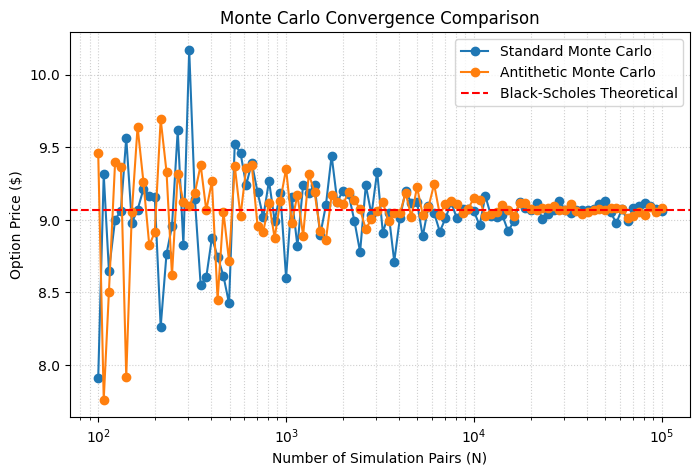

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

np.random.seed(42)

# Parameters
S0 = 100.0
K = 100.0
r = 0.05
# Assuming annualized_volatility was defined earlier
sigma = (
    annualized_volatility.item()
    if hasattr(annualized_volatility, "item")
    else annualized_volatility
)
T = 1.0
N = 100_000  # Number of pairs for Antithetic, base count for Standard

# ==========================================
# 1. Standard Monte Carlo (2*N total paths)
# ==========================================
N_total = 2 * N
Z_std = np.random.normal(0, 1, N_total)

ST_std = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z_std)
payoffs_std = np.maximum(ST_std - K, 0)
discounted_payoffs_std = np.exp(-r * T) * payoffs_std

mc_price = np.mean(discounted_payoffs_std)
# Divide by sqrt(len(discounted_payoffs_std)) which is sqrt(2*N)
mc_standard_error = np.std(discounted_payoffs_std, ddof=1) / np.sqrt(N_total)

# ==========================================
# 2. Antithetic Monte Carlo (N pairs = 2*N paths)
# ==========================================
Z_anti = np.random.normal(0, 1, N)

ST1 = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z_anti)
ST2 = S0 * np.exp((r - 0.5 * sigma**2) * T - sigma * np.sqrt(T) * Z_anti)

payoff1 = np.maximum(ST1 - K, 0)
payoff2 = np.maximum(ST2 - K, 0)

average_payoffs = (payoff1 + payoff2) / 2
discounted_antithetic_payoffs = np.exp(-r * T) * average_payoffs

antithetic_price = np.mean(discounted_antithetic_payoffs)
# Divided by sqrt(N) because we have N paired samples
antithetic_standard_error = np.std(
    discounted_antithetic_payoffs, ddof=1
) / np.sqrt(N)

# ==========================================
# 3. Black-Scholes Formula
# ==========================================
def call_price(S0, K, r, sigma, T):
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

bs_price = call_price(S0, K, r, sigma, T)

# ==========================================
# 4. Results & Metrics
# ==========================================
print(f"Black-Scholes:          ${bs_price:.4f}")
print(f"Monte Carlo:            ${mc_price:.4f}")
print(f"Antithetic Monte Carlo: ${antithetic_price:.4f}\n")

print(f"Standard MC SE:         ${mc_standard_error:.6f}")
print(f"Antithetic MC SE:       ${antithetic_standard_error:.6f}")

variance_reduction = (
    1 - (antithetic_standard_error**2 / mc_standard_error**2)
) * 100
print(f"Variance reduction:     {variance_reduction:.2f}%\n")

# ==========================================
# 5. Convergence Comparison Plot
# ==========================================
simulation_counts = np.logspace(2, 5, num=100, dtype=int)

mc_results = []
antithetic_results = []

for n in simulation_counts:
    # Standard MC using 2*n evaluations for equal computational effort
    Z_s = np.random.normal(0, 1, 2 * n)
    ST_s = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z_s)
    mc_results.append(np.mean(np.exp(-r * T) * np.maximum(ST_s - K, 0)))

    # Antithetic MC using n pairs (2*n evaluations)
    Z_a = np.random.normal(0, 1, n)
    ST_a1 = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z_a)
    ST_a2 = S0 * np.exp((r - 0.5 * sigma**2) * T - sigma * np.sqrt(T) * Z_a)
    avg_payoff = (np.maximum(ST_a1 - K, 0) + np.maximum(ST_a2 - K, 0)) / 2
    antithetic_results.append(np.mean(np.exp(-r * T) * avg_payoff))

plt.figure(figsize=(8, 5))
plt.plot(
    simulation_counts, mc_results, marker="o", label="Standard Monte Carlo"
)
plt.plot(
    simulation_counts,
    antithetic_results,
    marker="o",
    label="Antithetic Monte Carlo",
)
plt.axhline(
    bs_price, color="red", linestyle="--", label="Black-Scholes Theoretical"
)

plt.xscale("log")
plt.xlabel("Number of Simulation Pairs (N)")
plt.ylabel("Option Price ($)")
plt.title("Monte Carlo Convergence Comparison")
plt.legend()
plt.grid(True, which="both", linestyle=":", alpha=0.6)
plt.show()